In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from dataclasses import dataclass
from typing import Dict, List, Any, Tuple, Optional
import numpy as np
import copy

In [ ]:
# =============================================================================
# PROBLEM DEFINITION
# =============================================================================

TIME_HORIZON = 24

# Direct server cost per hour (¥/hour) - like on-demand compute pricing
# Cost varies by time slot (demand-based pricing)
SERVER_COST = {
    "M1": {  # GPU Compute - most expensive (training/inference)
        0: 80, 1: 80, 2: 80, 3: 80, 4: 80, 5: 80,      # off-peak
        6: 120, 7: 120, 8: 120, 9: 120,                 # morning peak
        10: 100, 11: 100, 12: 100, 13: 100, 14: 100, 15: 100, 16: 100,  # midday
        17: 140, 18: 140, 19: 140, 20: 140, 21: 140,   # evening peak (most expensive)
        22: 90, 23: 90                                  # late night
    },
    "M2": {  # CPU Compute - moderate cost (control logic, feature engineering)
        0: 20, 1: 20, 2: 20, 3: 20, 4: 20, 5: 20,
        6: 45, 7: 45, 8: 45, 9: 45,
        10: 30, 11: 30, 12: 30, 13: 30, 14: 30, 15: 30, 16: 30,
        17: 55, 18: 55, 19: 55, 20: 55, 21: 55,
        22: 25, 23: 25
    },
    "M3": {  # High-Memory Analytics - expensive (graphs, large matrices)
        0: 60, 1: 60, 2: 60, 3: 60, 4: 60, 5: 60,
        6: 95, 7: 95, 8: 95, 9: 95,
        10: 75, 11: 75, 12: 75, 13: 75, 14: 75, 15: 75, 16: 75,
        17: 110, 18: 110, 19: 110, 20: 110, 21: 110,
        22: 70, 23: 70
    },
    "M4": {  # Secure/Isolated Compute - premium cost (gov-only workloads)
        0: 50, 1: 50, 2: 50, 3: 50, 4: 50, 5: 50,
        6: 70, 7: 70, 8: 70, 9: 70,
        10: 60, 11: 60, 12: 60, 13: 60, 14: 60, 15: 60, 16: 60,
        17: 80, 18: 80, 19: 80, 20: 80, 21: 80,
        22: 55, 23: 55
    },
    "M5": {  # Data Ingest & Preprocessing - cheapest (IO-heavy, staging)
        0: 15, 1: 15, 2: 15, 3: 15, 4: 15, 5: 15,
        6: 30, 7: 30, 8: 30, 9: 30,
        10: 22, 11: 22, 12: 22, 13: 22, 14: 22, 15: 22, 16: 22,
        17: 35, 18: 35, 19: 35, 20: 35, 21: 35,
        22: 18, 23: 18
    },
    # Cloud machines - 5x cost, infinite capacity
    "C1": {  # Cloud GPU
        0: 400, 1: 400, 2: 400, 3: 400, 4: 400, 5: 400,
        6: 600, 7: 600, 8: 600, 9: 600,
        10: 500, 11: 500, 12: 500, 13: 500, 14: 500, 15: 500, 16: 500,
        17: 700, 18: 700, 19: 700, 20: 700, 21: 700,
        22: 450, 23: 450
    },
    "C2": {  # Cloud CPU
        0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100,
        6: 225, 7: 225, 8: 225, 9: 225,
        10: 150, 11: 150, 12: 150, 13: 150, 14: 150, 15: 150, 16: 150,
        17: 275, 18: 275, 19: 275, 20: 275, 21: 275,
        22: 125, 23: 125
    },
    "C3": {  # Cloud HighMem
        0: 300, 1: 300, 2: 300, 3: 300, 4: 300, 5: 300,
        6: 475, 7: 475, 8: 475, 9: 475,
        10: 375, 11: 375, 12: 375, 13: 375, 14: 375, 15: 375, 16: 375,
        17: 550, 18: 550, 19: 550, 20: 550, 21: 550,
        22: 350, 23: 350
    },
    "C4": {  # Cloud Secure
        0: 250, 1: 250, 2: 250, 3: 250, 4: 250, 5: 250,
        6: 350, 7: 350, 8: 350, 9: 350,
        10: 300, 11: 300, 12: 300, 13: 300, 14: 300, 15: 300, 16: 300,
        17: 400, 18: 400, 19: 400, 20: 400, 21: 400,
        22: 275, 23: 275
    },
    "C5": {  # Cloud Ingest
        0: 75, 1: 75, 2: 75, 3: 75, 4: 75, 5: 75,
        6: 150, 7: 150, 8: 150, 9: 150,
        10: 110, 11: 110, 12: 110, 13: 110, 14: 110, 15: 110, 16: 110,
        17: 175, 18: 175, 19: 175, 20: 175, 21: 175,
        22: 90, 23: 90
    },
}

@dataclass
class Server:
    id: str
    server_type: str
    capacity: int  # Available capacity units
    is_cloud: bool = False  # Cloud machines have infinite capacity but 5x cost

@dataclass
class Operation:
    server_type: str
    duration: int
    capacity_required: int = 1  # Capacity units consumed during execution

@dataclass
class Job:
    id: str
    description: str
    priority: str
    deadline: int
    delay_weight: float
    operations: List[Operation]

@dataclass
class Instance:
    servers: Dict[str, Server]
    jobs: Dict[str, Job]
    server_cost: Dict[str, Dict[int, float]]  # server_id -> {hour: cost}
    time_horizon: int
    weights: Dict[str, float]

Schedule = Dict[str, List[Dict[str, Any]]]

def create_instance() -> Instance:
    servers = {
        "M1": Server("M1", "GPU", capacity=20, is_cloud=False),
        "M2": Server("M2", "CPU", capacity=40, is_cloud=False),
        "M3": Server("M3", "HighMem", capacity=10, is_cloud=False),
        "M4": Server("M4", "Secure", capacity=5, is_cloud=False),
        "M5": Server("M5", "Ingest", capacity=30, is_cloud=False),
        # Cloud overflow machines (infinite capacity, 5x cost)
        "C1": Server("C1", "GPU", capacity=999999, is_cloud=True),
        "C2": Server("C2", "CPU", capacity=999999, is_cloud=True),
        "C3": Server("C3", "HighMem", capacity=999999, is_cloud=True),
        "C4": Server("C4", "Secure", capacity=999999, is_cloud=True),
        "C5": Server("C5", "Ingest", capacity=999999, is_cloud=True),
    }
    jobs = {
        "J1": Job("J1", "National census data processing", "HIGH", 12, 10.0, [
            Operation("Ingest", 2, 5), Operation("HighMem", 3, 3), Operation("CPU", 2, 4)
        ]),
        "J2": Job("J2", "Tax fraud detection ML model", "HIGH", 10, 8.0, [
            Operation("Ingest", 1, 3), Operation("GPU", 3, 8), Operation("CPU", 1, 2)
        ]),
        "J3": Job("J3", "Emergency response coordination", "CRITICAL", 6, 15.0, [
            Operation("Secure", 2, 2), Operation("CPU", 1, 3), Operation("HighMem", 1, 2)
        ]),
        "J4": Job("J4", "Geospatial infrastructure analysis", "MEDIUM", 16, 5.0, [
            Operation("Ingest", 2, 4), Operation("HighMem", 4, 5)
        ]),
        "J5": Job("J5", "Classified intelligence processing", "CRITICAL", 8, 12.0, [
            Operation("Secure", 3, 3), Operation("Secure", 2, 2)
        ]),
        "J6": Job("J6", "Public health data aggregation", "MEDIUM", 18, 4.0, [
            Operation("Ingest", 1, 2), Operation("CPU", 2, 5), Operation("HighMem", 2, 3)
        ]),
        "J7": Job("J7", "Climate model training", "LOW", 20, 2.0, [
            Operation("Ingest", 1, 3), Operation("GPU", 4, 10)
        ]),
        "J8": Job("J8", "Social services optimization", "MEDIUM", 14, 6.0, [
            Operation("Ingest", 1, 3), Operation("CPU", 2, 6), Operation("HighMem", 2, 4)
        ]),
    }
    return Instance(servers, jobs, SERVER_COST, TIME_HORIZON, 
                   {"compute_cost": 1.0, "delay_penalty": 5.0})

INSTANCE = create_instance()
print(f"Instance: {len(INSTANCE.jobs)} jobs, {len(INSTANCE.servers)} servers")


Instance: 6 jobs, 4 servers


: 

In [ ]:
# =============================================================================
# FITNESS EVALUATION
# =============================================================================

@dataclass
class Fitness:
    score: float
    compute_cost: float
    delay_penalty: float
    violations: List[str]
    job_completion_times: Dict[str, int]
    
    def is_valid(self) -> bool:
        return len(self.violations) == 0


def evaluate(inst: Instance, schedule: Schedule) -> Fitness:
    """Evaluate a schedule with capacity constraints."""
    violations = []
    total_compute_cost = 0
    total_delay_penalty = 0
    job_completion_times = {}
    
    # Track capacity usage per machine per timestep
    capacity_usage = {s: {} for s in inst.servers}

    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        if len(ops) != len(job.operations):
            violations.append(f"{job_id}: wrong number of operations")
            continue

        prev_end = None
        for idx, op in enumerate(ops):
            server_id = op["server"]
            start = op["start"]
            duration = job.operations[idx].duration
            capacity_req = job.operations[idx].capacity_required
            end = start + duration

            if prev_end is not None and start < prev_end:
                violations.append(f"{job_id}: op {idx} starts before previous ends")
            prev_end = end

            required_type = job.operations[idx].server_type
            actual_type = inst.servers[server_id].server_type
            if required_type != actual_type:
                violations.append(f"{job_id}: op {idx} requires {required_type}, got {actual_type}")

            # Track capacity usage for each timestep
            for t in range(start, end):
                if t not in capacity_usage[server_id]:
                    capacity_usage[server_id][t] = 0
                capacity_usage[server_id][t] += capacity_req
            
            # Calculate cost
            for t in range(start, end):
                total_compute_cost += inst.server_cost[server_id][t % inst.time_horizon]

        completion = prev_end if prev_end else 0
        job_completion_times[job_id] = completion
        delay = max(0, completion - job.deadline)
        total_delay_penalty += delay * job.delay_weight

    # Check capacity constraints for each machine at each timestep
    for server_id, usage_by_time in capacity_usage.items():
        for time, used_capacity in usage_by_time.items():
            available_capacity = inst.servers[server_id].capacity
            if used_capacity > available_capacity:
                violations.append(
                    f"{server_id}: capacity exceeded at t={time} "
                    f"(used: {used_capacity}, available: {available_capacity})"
                )

    score = (inst.weights["compute_cost"] * total_compute_cost +
             inst.weights["delay_penalty"] * total_delay_penalty +
             len(violations) * 10000)

    return Fitness(round(score, 2), round(total_compute_cost, 2),
                   round(total_delay_penalty, 2), violations, job_completion_times)


: 

In [ ]:
# EVOLVE-BLOCK-START

def construct_schedule(inst: Instance) -> Schedule:
    """
    FIFO scheduler with capacity awareness and cloud overflow.
    Jobs are scheduled in order, using local machines when capacity available,
    otherwise using cloud resources.

    Args:
        inst: Problem instance with servers, jobs, server costs

    Returns:
        Schedule: Dict mapping job_id -> list of {"server": str, "start": int}
    """
    def get_servers_by_type(server_type: str, prefer_local: bool = True) -> List[str]:
        """Get servers of a given type, optionally preferring local over cloud."""
        servers = [s.id for s in inst.servers.values() if s.server_type == server_type]
        if prefer_local:
            # Sort: local machines first, then cloud
            servers.sort(key=lambda s: inst.servers[s].is_cloud)
        return servers
    
    def has_capacity(server_id: str, start: int, duration: int, capacity_req: int) -> bool:
        """Check if server has enough capacity for the entire operation duration."""
        for t in range(start, start + duration):
            used = capacity_usage[server_id].get(t, 0)
            available = inst.servers[server_id].capacity
            if used + capacity_req > available:
                return False
        return True
    
    # Track capacity usage per machine per timestep
    capacity_usage = {s: {} for s in inst.servers}
    
    # Track when each job can start (after its previous operation finishes)
    job_available_time = {j: 0 for j in inst.jobs}
    
    schedule = {}
    
    # FIFO: Process jobs in order (sorted by priority, then deadline)
    priority_order = {"CRITICAL": 0, "HIGH": 1, "MEDIUM": 2, "LOW": 3}
    sorted_jobs = sorted(inst.jobs.keys(),
                        key=lambda j: (priority_order[inst.jobs[j].priority],
                                      inst.jobs[j].deadline, j))
    
    for job_id in sorted_jobs:
        job = inst.jobs[job_id]
        schedule[job_id] = []
        
        for op in job.operations:
            # Get compatible servers (local first, then cloud)
            compatible = get_servers_by_type(op.server_type, prefer_local=True)
            
            scheduled = False
            earliest_start = job_available_time[job_id]
            
            # Try to schedule on local machines first
            for server_id in compatible:
                if inst.servers[server_id].is_cloud:
                    continue  # Skip cloud for now, try local first
                
                # Find earliest time this operation can start on this server
                for start_time in range(earliest_start, inst.time_horizon):
                    if start_time + op.duration > inst.time_horizon:
                        break
                    
                    # Check if server has capacity
                    if has_capacity(server_id, start_time, op.duration, op.capacity_required):
                        # Reserve capacity
                        for t in range(start_time, start_time + op.duration):
                            if t not in capacity_usage[server_id]:
                                capacity_usage[server_id][t] = 0
                            capacity_usage[server_id][t] += op.capacity_required
                        
                        schedule[job_id].append({"server": server_id, "start": start_time})
                        job_available_time[job_id] = start_time + op.duration
                        scheduled = True
                        break
                
                if scheduled:
                    break
            
            # If no local machine available, use cloud resources
            if not scheduled:
                for server_id in compatible:
                    if not inst.servers[server_id].is_cloud:
                        continue  # Only cloud now
                    
                    # Cloud has infinite capacity, just schedule at earliest time
                    start_time = earliest_start
                    
                    # Reserve capacity (cloud has effectively infinite)
                    for t in range(start_time, start_time + op.duration):
                        if t not in capacity_usage[server_id]:
                            capacity_usage[server_id][t] = 0
                        capacity_usage[server_id][t] += op.capacity_required
                    
                    schedule[job_id].append({"server": server_id, "start": start_time})
                    job_available_time[job_id] = start_time + op.duration
                    scheduled = True
                    break
            
            # Fallback: if still not scheduled (shouldn't happen), use first compatible
            if not scheduled:
                server_id = compatible[0]
                start_time = earliest_start
                schedule[job_id].append({"server": server_id, "start": start_time})
                job_available_time[job_id] = start_time + op.duration
    
    return schedule

# EVOLVE-BLOCK-END


def run_scheduling():
    """Run the schedule constructor and return results."""
    schedule = construct_schedule(INSTANCE)
    fitness = evaluate(INSTANCE, schedule)
    return schedule, fitness


np.random.seed(42)
schedule, fitness = run_scheduling()
print(f"Score: {fitness.score}")
print(f"Compute Cost: {fitness.compute_cost}")
print(f"Delay Penalty: {fitness.delay_penalty}")
print(f"Valid: {fitness.is_valid()}")


Score: 409.6
Energy Cost: 409.6
Delay Penalty: 0.0
Valid: True


: 

In [28]:
# =============================================================================
# VALIDATION
# =============================================================================

def validate_schedule(
    run_output: Tuple[Schedule, Fitness],
    inst: Instance = INSTANCE,
    atol: float = 1e-7
) -> Tuple[bool, Optional[str]]:
    """
    Validates schedule results based on the output of 'run_scheduling'.
    
    Args:
        run_output: Tuple (schedule, fitness) from run_scheduling.
        inst: Problem instance.
        atol: Absolute tolerance for numerical checks.
    
    Returns:
        (is_valid: bool, error_message: Optional[str])
    """
    schedule, fitness = run_output
    
    # Check all jobs are scheduled
    if set(schedule.keys()) != set(inst.jobs.keys()):
        missing = set(inst.jobs.keys()) - set(schedule.keys())
        extra = set(schedule.keys()) - set(inst.jobs.keys())
        return False, f"Job mismatch. Missing: {missing}, Extra: {extra}"
    
    # Check operation counts
    for job_id, ops in schedule.items():
        expected = len(inst.jobs[job_id].operations)
        if len(ops) != expected:
            return False, f"{job_id}: expected {expected} ops, got {len(ops)}"
    
    # Check server type compatibility
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op_sched in enumerate(ops):
            required = job.operations[idx].server_type
            actual = inst.servers[op_sched["server"]].server_type
            if required != actual:
                return False, f"{job_id} op {idx}: requires {required}, assigned {actual}"
    
    # Check job precedence constraints
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        prev_end = 0
        for idx, op_sched in enumerate(ops):
            start = op_sched["start"]
            duration = job.operations[idx].duration
            if start < prev_end:
                return False, f"{job_id} op {idx}: starts at {start} before prev ends at {prev_end}"
            prev_end = start + duration
    
    # Check server capacity (no overlaps)
    server_intervals = {s: [] for s in inst.servers}
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op_sched in enumerate(ops):
            server = op_sched["server"]
            start = op_sched["start"]
            end = start + job.operations[idx].duration
            server_intervals[server].append((start, end, job_id))
    
    for server, intervals in server_intervals.items():
        intervals.sort()
        for i in range(len(intervals) - 1):
            _, end1, job1 = intervals[i]
            start2, _, job2 = intervals[i + 1]
            if start2 < end1:
                return False, f"{server}: overlap between {job1} (ends {end1}) and {job2} (starts {start2})"
    
    # Check non-negative start times
    for job_id, ops in schedule.items():
        for idx, op_sched in enumerate(ops):
            if op_sched["start"] < 0:
                return False, f"{job_id} op {idx}: negative start time {op_sched['start']}"
    
    # Check fitness violations match
    if fitness.violations:
        return False, f"Fitness has violations: {fitness.violations}"
    
    return True, None


# Run validation
is_valid, error = validate_schedule((schedule, fitness))
print(f"Valid: {is_valid}")
if error:
    print(f"Error: {error}")

Valid: True


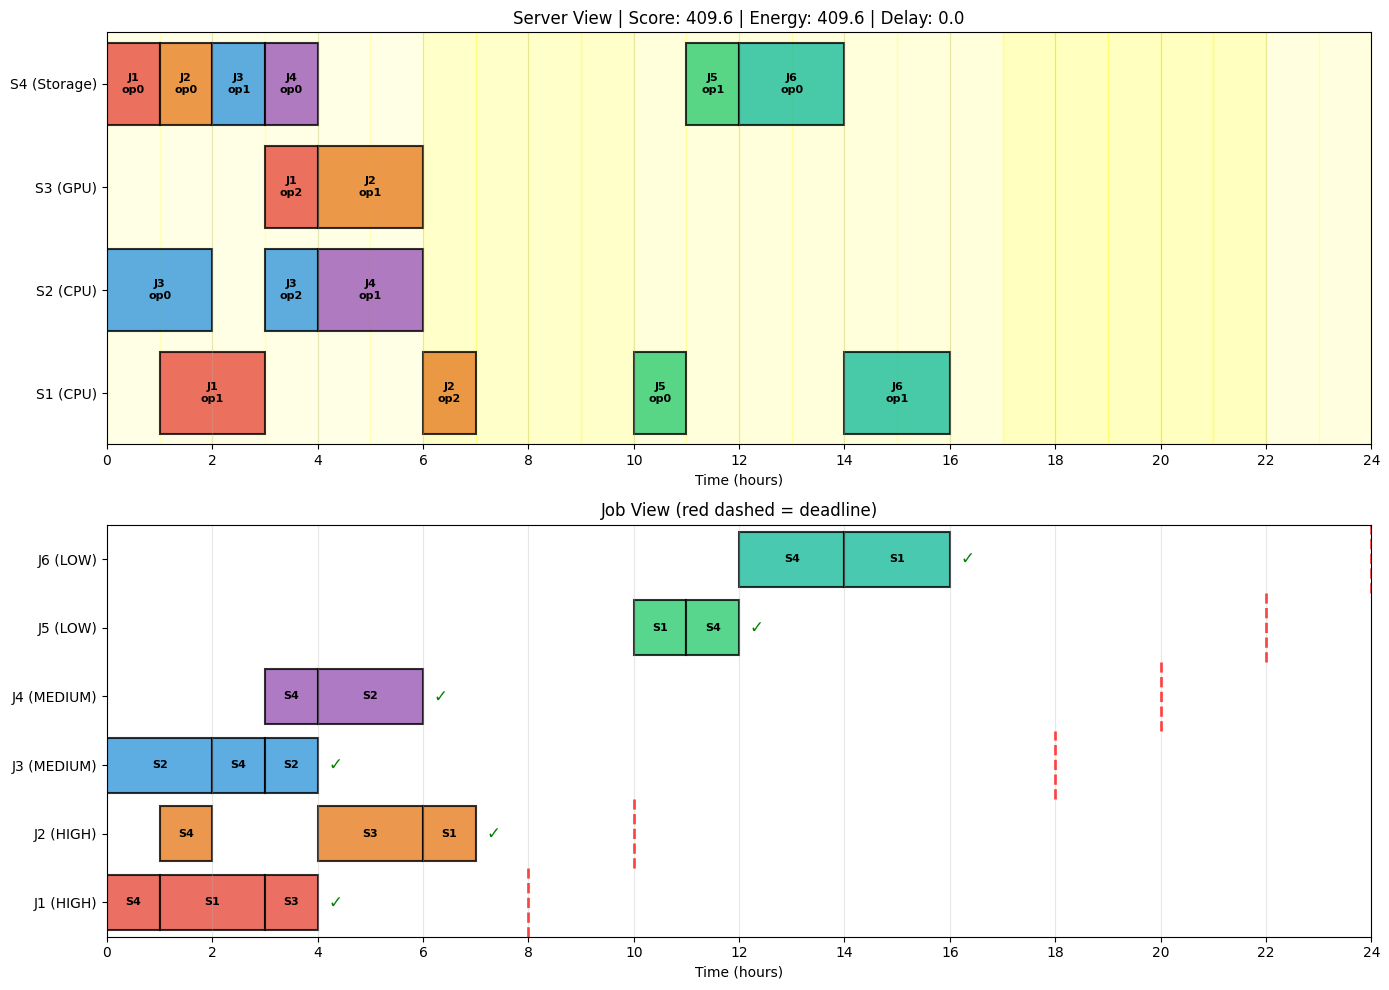

In [ ]:
# =============================================================================
# VISUALIZATION - Gantt Chart
# =============================================================================

def visualize_schedule(schedule: Schedule, inst: Instance, fitness: Fitness):
    """
    Visualize the schedule as a Gantt chart with two views:
    1. Server view (which jobs run on each server)
    2. Job view (timeline of each job's operations)
    """
    # Color palette for jobs
    job_colors = {
        "J1": "#e74c3c",  # red (HIGH)
        "J2": "#c0392b",  # dark red (HIGH)
        "J3": "#8e44ad",  # purple (CRITICAL)
        "J4": "#3498db",  # blue (MEDIUM)
        "J5": "#9b59b6",  # violet (CRITICAL)
        "J6": "#16a085",  # teal (MEDIUM)
        "J7": "#27ae60",  # green (LOW)
        "J8": "#2980b9",  # ocean blue (MEDIUM)
    }
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    
    # --- Server View (Top) ---
    ax1 = axes[0]
    servers = list(inst.servers.keys())
    server_y = {s: i for i, s in enumerate(servers)}
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op_sched in enumerate(ops):
            server = op_sched["server"]
            start = op_sched["start"]
            duration = job.operations[idx].duration
            y = server_y[server]
            
            rect = Rectangle((start, y - 0.4), duration, 0.8,
                            facecolor=job_colors[job_id], edgecolor='black',
                            linewidth=1.5, alpha=0.8)
            ax1.add_patch(rect)
            ax1.text(start + duration/2, y, f"{job_id}\nop{idx}",
                    ha='center', va='center', fontsize=8, fontweight='bold')
    
    # Draw cost background (average across servers)
    for t in range(inst.time_horizon):
        avg_cost = sum(inst.server_cost[s][t] for s in servers) / len(servers)
        alpha = 0.05 + 0.15 * (avg_cost - 18) / 50  # Normalize to 0.05-0.20
        ax1.axvspan(t, t+1, alpha=max(0.05, alpha), color='yellow', zorder=0)
    
    ax1.set_xlim(0, inst.time_horizon)
    ax1.set_ylim(-0.5, len(servers) - 0.5)
    ax1.set_yticks(range(len(servers)))
    ax1.set_yticklabels([f"{s} ({inst.servers[s].server_type})" for s in servers])
    ax1.set_xlabel("Time (hours)")
    ax1.set_title(f"Server View | Score: {fitness.score} | Cost: ¥{fitness.compute_cost} | Delay: {fitness.delay_penalty}")
    ax1.grid(True, axis='x', alpha=0.3)
    ax1.set_xticks(range(0, inst.time_horizon + 1, 2))
    
    # --- Job View (Bottom) ---
    ax2 = axes[1]
    jobs = list(inst.jobs.keys())
    job_y = {j: i for i, j in enumerate(jobs)}
    
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        y = job_y[job_id]
        
        for idx, op_sched in enumerate(ops):
            server = op_sched["server"]
            start = op_sched["start"]
            duration = job.operations[idx].duration
            
            rect = Rectangle((start, y - 0.4), duration, 0.8,
                            facecolor=job_colors[job_id], edgecolor='black',
                            linewidth=1.5, alpha=0.8)
            ax2.add_patch(rect)
            ax2.text(start + duration/2, y, f"{server}",
                    ha='center', va='center', fontsize=8, fontweight='bold')
        
        # Draw deadline marker
        ax2.axvline(x=job.deadline, ymin=(y - 0.5 + 0.5) / len(jobs),
                   ymax=(y + 0.5 + 0.5) / len(jobs),
                   color='red', linestyle='--', linewidth=2, alpha=0.7)
        
        # Mark completion time
        completion = fitness.job_completion_times.get(job_id, 0)
        marker = '✓' if completion <= job.deadline else '✗'
        color = 'green' if completion <= job.deadline else 'red'
        ax2.text(completion + 0.2, y, marker, fontsize=12, color=color, va='center')
    
    ax2.set_xlim(0, inst.time_horizon)
    ax2.set_ylim(-0.5, len(jobs) - 0.5)
    ax2.set_yticks(range(len(jobs)))
    ax2.set_yticklabels([f"{j} ({inst.jobs[j].priority})" for j in jobs])
    ax2.set_xlabel("Time (hours)")
    ax2.set_title("Job View (red dashed = deadline)")
    ax2.grid(True, axis='x', alpha=0.3)
    ax2.set_xticks(range(0, inst.time_horizon + 1, 2))
    
    plt.tight_layout()
    return fig, axes


fig, axes = visualize_schedule(schedule, INSTANCE, fitness)

fig.savefig("schedule_gantt.pdf", bbox_inches="tight", dpi=300)plt.show()

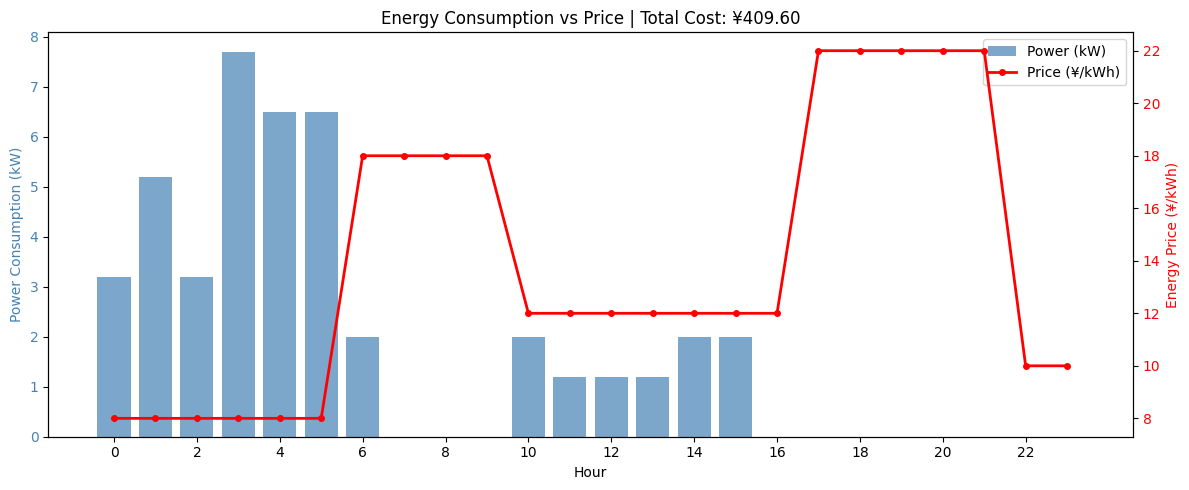

In [ ]:
# =============================================================================
# SERVER COST VISUALIZATION
# =============================================================================

def visualize_cost_usage(schedule: Schedule, inst: Instance):
    """Visualize compute cost over time with server price overlay."""
    fig, ax1 = plt.subplots(figsize=(12, 5))
    
    # Calculate cost per hour
    cost_by_hour = [0.0] * inst.time_horizon
    for job_id, ops in schedule.items():
        job = inst.jobs[job_id]
        for idx, op_sched in enumerate(ops):
            server = op_sched["server"]
            start = op_sched["start"]
            duration = job.operations[idx].duration
            for t in range(start, start + duration):
                if t < inst.time_horizon:
                    cost_by_hour[t] += inst.server_cost[server][t]
    
    # Plot hourly cost
    hours = list(range(inst.time_horizon))
    ax1.bar(hours, cost_by_hour, color='steelblue', alpha=0.7, label='Hourly Cost (¥)')
    ax1.set_xlabel('Hour')
    ax1.set_ylabel('Compute Cost (¥)', color='steelblue')
    ax1.tick_params(axis='y', labelcolor='steelblue')
    
    # Plot average server prices on secondary axis
    ax2 = ax1.twinx()
    avg_prices = [sum(inst.server_cost[s][t] for s in inst.servers) / len(inst.servers) for t in hours]
    ax2.plot(hours, avg_prices, color='red', linewidth=2, marker='o', markersize=4, label='Avg Price (¥/h)')
    ax2.set_ylabel('Avg Server Price (¥/hour)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    
    total_cost = sum(cost_by_hour)
    
    ax1.set_title(f'Compute Cost Over Time | Total Cost: ¥{total_cost:.2f}')
    ax1.set_xticks(range(0, inst.time_horizon, 2))
    
    # Add legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
    
    plt.tight_layout()
    return fig, (ax1, ax2)


fig, axes = visualize_cost_usage(schedule, INSTANCE)
fig.savefig("cost_usage.pdf", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
# =============================================================================
# SCHEDULE SUMMARY
# =============================================================================

def print_schedule_summary(schedule: Schedule, inst: Instance, fitness: Fitness):
    """Print a detailed summary of the schedule."""
    print("=" * 60)
    print("SCHEDULE SUMMARY")
    print("=" * 60)
    print(f"\nObjective Score: {fitness.score}")
    print(f"  - Compute Cost: ¥{fitness.compute_cost}")
    print(f"  - Delay Penalty: {fitness.delay_penalty}")
    print(f"  - Valid: {fitness.is_valid()}")
    
    print("\n" + "-" * 60)
    print("JOB DETAILS")
    print("-" * 60)
    
    for job_id in sorted(schedule.keys()):
        job = inst.jobs[job_id]
        completion = fitness.job_completion_times.get(job_id, 0)
        delay = max(0, completion - job.deadline)
        status = "✓ ON TIME" if delay == 0 else f"✗ LATE by {delay}h"
        
        print(f"\n{job_id} ({job.priority}): {job.description}")
        print(f"  Deadline: {job.deadline}h | Completed: {completion}h | {status}")
        print(f"  Operations:")
        
        for idx, op_sched in enumerate(schedule[job_id]):
            op = job.operations[idx]
            server = op_sched["server"]
            start = op_sched["start"]
            end = start + op.duration
            cost = sum(inst.server_cost[server][t] for t in range(start, end))
            print(f"    [{idx}] {op.server_type} on {server}: t={start}-{end} (¥{cost})")


print_schedule_summary(schedule, INSTANCE, fitness)

SCHEDULE SUMMARY

Objective Score: 409.6
  - Energy Cost: ¥409.6
  - Delay Penalty: 0.0
  - Valid: True

------------------------------------------------------------
JOB DETAILS
------------------------------------------------------------

J1 (HIGH): Emergency response analytics
  Deadline: 8h | Completed: 4h | ✓ ON TIME
  Operations:
    [0] Storage on S4: t=0-1
    [1] CPU on S1: t=1-3
    [2] GPU on S3: t=3-4

J2 (HIGH): Disaster damage estimation
  Deadline: 10h | Completed: 7h | ✓ ON TIME
  Operations:
    [0] Storage on S4: t=1-2
    [1] GPU on S3: t=4-6
    [2] CPU on S1: t=6-7

J3 (MEDIUM): Tax data aggregation
  Deadline: 18h | Completed: 4h | ✓ ON TIME
  Operations:
    [0] CPU on S2: t=0-2
    [1] Storage on S4: t=2-3
    [2] CPU on S2: t=3-4

J4 (MEDIUM): Census preprocessing
  Deadline: 20h | Completed: 6h | ✓ ON TIME
  Operations:
    [0] Storage on S4: t=3-4
    [1] CPU on S2: t=4-6

J5 (LOW): Open data batch update
  Deadline: 22h | Completed: 12h | ✓ ON TIME
  Operatio